# 07 · Follow the food, not just the fleet

[Run this notebook in your browser ↗](https://jltobias.github.io/JupyterLite-Global-Fishing-Watch-and-Dark-Vessels/lab/index.html?path=07_food_and_equity.ipynb)

**Evidence: synthetic food-accounting scenarios.** Hold catch constant while changing distribution and losses. The model estimates potential edible availability, not intake, clinical benefit or dietary adequacy.

Context: [FAO/WHO risks and benefits of fish consumption](https://www.who.int/publications/i/item/9789240096882) and [WHO One Health](https://www.who.int/publications/m/item/one-health-definitions-and-principles). The protein fraction below is an illustrative assumption, not species composition data.

Run the setup cell first. Browser Python downloads numerical packages on first use. Core exercises use bundled files; live access is optional. Export your notebook to preserve work.

In [1]:
import sys
if sys.platform == "emscripten":
    import micropip
    await micropip.install(["numpy", "pandas", "matplotlib", "scipy", "plotly"])
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import oceanlab as lab
from IPython.display import display
print("Runtime:", sys.version.split()[0], "| NumPy:", np.__version__, "| pandas:", pd.__version__)

Runtime: 3.13.14 | NumPy: 2.3.3 | pandas: 2.3.2


## Put units into the pathway
Potential edible kilograms = catch tonnes × 1000 × local retention × edible fraction × (1 − loss). Divide by population and days, then convert kilograms to grams. This accounting includes no trade imports, household allocation, seasonality, or dietary substitution.

In [2]:
RETENTION=.45
EDIBLE_FRACTION=.65
LOSS=.15
result=lab.food_scenario(retention=RETENTION,edible_fraction=EDIBLE_FRACTION,loss=LOSS)
display(pd.Series(result))
rows=[]
for retention in [.2,.45,.7]:
    for loss in [.05,.15,.3]:
        rows.append({"retention":retention,"loss":loss,**lab.food_scenario(retention=retention,loss=loss)})
scenarios=pd.DataFrame(rows)
display(scenarios.round(2))

edible_kg                     248625.000000
grams_per_person_per_day           6.811644
illustrative_protein_g_day         1.362329
dtype: float64

,retention,loss,edible_kg,grams_per_person_per_day,illustrative_protein_g_day
0,0.20,0.05,123500.0,3.38,0.68
1,0.20,0.15,110500.0,3.03,0.61
2,0.20,0.30,91000.0,2.49,0.50
3,0.45,0.05,277875.0,7.61,1.52
4,0.45,0.15,248625.0,6.81,1.36
5,0.45,0.30,204750.0,5.61,1.12
6,0.70,0.05,432250.0,11.84,2.37
7,0.70,0.15,386750.0,10.60,2.12
8,0.70,0.30,318500.0,8.73,1.75


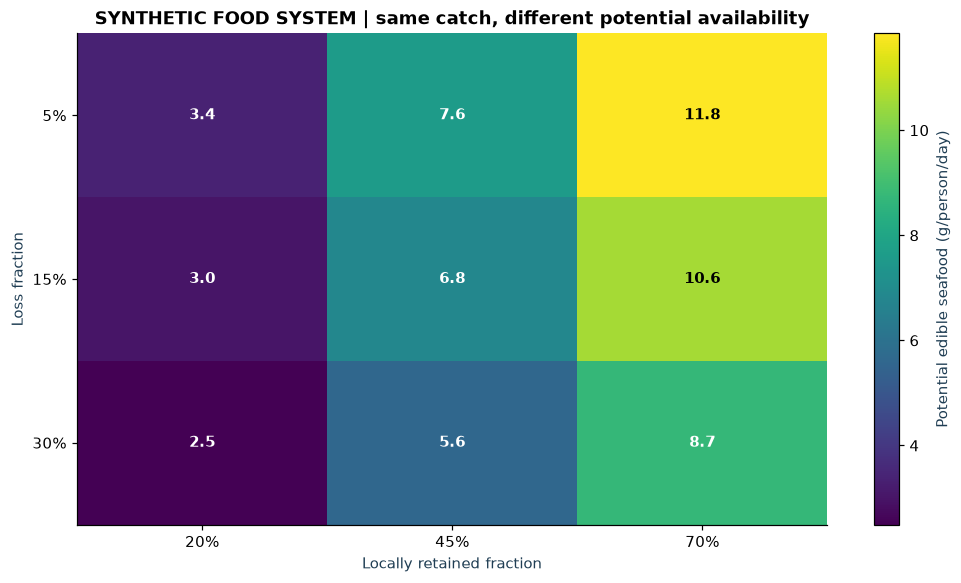

In [3]:
table=scenarios.pivot(index="loss",columns="retention",values="grams_per_person_per_day")
fig,ax=plt.subplots()
p=ax.imshow(table.to_numpy(),cmap="viridis",aspect="auto")
ax.set_xticks(range(len(table.columns)),[f"{x:.0%}" for x in table.columns])
ax.set_yticks(range(len(table.index)),[f"{x:.0%}" for x in table.index])
for i in range(len(table.index)):
    for j in range(len(table.columns)):
        ax.text(j,i,f"{table.iloc[i,j]:.1f}",ha="center",va="center",color="white" if table.iloc[i,j]<10 else "black",fontweight="bold")
ax.set(xlabel="Locally retained fraction",ylabel="Loss fraction",title="SYNTHETIC FOOD SYSTEM | same catch, different potential availability")
fig.colorbar(p,ax=ax,label="Potential edible seafood (g/person/day)")
plt.show()

## Who experiences the average?
An equal-per-person average is not evidence of equal access. The same regional availability can coexist with severe household differences in income, prices, storage, landings access, age, gender and cultural preferences. Fishing workers can also face exposure and safety risks that a food total hides.

In [4]:
# Invented allocation: 20% of the population receives 60% of local edible supply.
total=result["edible_kg"]
allocation=pd.DataFrame({"group":["A","B"],"population":[20000,80000],"supply_share":[.60,.40]})
allocation["available_g_person_day"]=total*allocation.supply_share*1000/allocation.population/365
display(allocation)
print("Synthetic allocation only; groups are not real demographic categories.")

,group,population,supply_share,available_g_person_day
0,A,20000,0.6,20.434932
1,B,80000,0.4,3.405822


Synthetic allocation only; groups are not real demographic categories.


## A decision that needs more evidence
Reducing losses may increase availability, but intervention cost, worker conditions, energy requirements and food safety also matter. Greater local retention may change earnings and trade relationships. Communities should help define the objective.

**Try it:** choose two interventions that produce similar average availability. Identify how their distributional effects and costs could differ. State which household or market measurements you would collect before choosing between them.